In [39]:

import os, sys, math, glob, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from scipy.signal import welch, butter, filtfilt
from scipy.stats import kurtosis
import mne

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    try:
        print("GPU:", torch.cuda.get_device_name(0))
    except:
        pass


Device: cuda
GPU: NVIDIA GeForce GTX 1650 Ti


##Cell 2: Checking GPU Availability and Importing the dataset
1) Creates a Subjects Range from 1 to 66 patients  
2) sampling rate in dataset = 500 readings every second
3) 5-second windows --> cuts EEG data into 5-second pieces
4) 50% overlap --> 50% overlap between EEG segments
5) number of Channels = 19

In [40]:
##Cell 2
datasetPath = r"/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG"  
subjects = [f"sub-{i:03d}" for i in range(1,66)]  
fs_target = 500  # sampling rate in dataset (already 500)
seg_sec = 5      # 5-second windows
overlap = 0.5    # 50% overlap
window_samples = int(seg_sec * fs_target)
step_samples = int(window_samples * (1 - overlap))
n_channels_expected = 19
save_dir = Path("results_bilstm")
save_dir.mkdir(exist_ok=True)


In [41]:
# Cell 3: ueses wavelet-packet proxy

In [42]:
# Cell 3
use_tqwt = False
try:
    import tqwt  # preferred package if available
    use_tqwt = True
    print("tqwt package available.")
except Exception as e:
    print("tqwt not found. Will use fallback (wavelet-packet approx) if necessary.")
    use_tqwt = False

# Fallback: we'll use pywt WaveletPacket as approximate multi-band split when tqwt unavailable
try:
    import pywt
    has_pywt = True
except:
    has_pywt = False
    raise ImportError("pywt not installed. Please install pywt (pip install PyWavelets).")


tqwt not found. Will use fallback (wavelet-packet approx) if necessary.


Cell 4: 
This cell extracts useful information (features) from raw 
EEG signals so that the Bi-LSTM model can understand them better.
Entropy --> quantify the impurity, disorder, or uncertainty within a dataset.
1) shannon_entropy --> How random or unpredictable the EEG signal is
2) tsallis_entropy --> Finding rare spikes in EEG that normal measures might miss
3) renyi_entropy --> Measures how concentrated the EEG signal is
4) katz_fd --> Signal complexity,How rough or jagged the EEG signal is
5) kurtosis_feature --> Peakedness of the EEG signal

In [43]:
# Cell 4: feature functions
def shannon_entropy(x, bins=100):
    p, _ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return -np.sum(p * np.log2(p))

def tsallis_entropy(x, q=2.0, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    if q == 1.0:
        return -np.sum(p * np.log(p))
    return (1.0 - np.sum(p**q)) / (q - 1.0)

def renyi_entropy(x, q=0.5, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return (1.0/(1.0 - q)) * np.log(np.sum(p**q))

def katz_fd(x):
    x = np.asarray(x)
    n = len(x)
    if n < 2:
        return 0.0
    L = np.sum(np.sqrt(1 + np.diff(x)**2))
    d = np.max(np.sqrt((np.arange(n) - 0)**2 + (x - x[0])**2))
    if L == 0 or d == 0:
        return 0.0
    return np.log10(n) / (np.log10(n) + np.log10(d / L))

def kurtosis_feature(x):
    return float(kurtosis(x, fisher=False, nan_policy='omit'))

# wrapper to compute 4 features from a 1D subband
def features_from_subband(x):
    x = np.asarray(x)
    if x.std() == 0:
        x = x - x.mean()
    return [katz_fd(x), tsallis_entropy(x, q=2.0), renyi_entropy(x, q=0.5), kurtosis_feature(x)]


In [44]:
# Cell 5: estimate Q,R,J from signal power (simple heuristic)
def estimate_tqwt_params(signal, fs):
    # PSD to find dominant freq f0 and approximate bandwidth
    f, Pxx = welch(signal, fs=fs, nperseg=min(len(signal), 2048))## Welches Methods 
    f0 = f[np.argmax(Pxx)]                                       ##Finds frequency with maximum power(This is the strongest brain rhythm)
    # half-power bandwidth approx
    peak = np.max(Pxx)
    inds = np.where(Pxx >= peak/2)[0]
    if len(inds) > 1:
        bw = f[inds[-1]] - f[inds[0]]
    else:
        bw = max(1.0, f0*0.5)
    Q = max(0.5, float(f0) / max(bw, 1e-6))
    # redundancy heuristic: bound between 2 and 12
    R = int(np.clip(fs / (2 * max(f0,1.0)), 2, 12))
    # J selection: want ~2 Hz subband width: J ~ log2((fs/2)/target_bw)
    target_bw = 2.0
    J = int(np.clip(np.floor(np.log2((fs/2)/target_bw)), 3, 8))
    return float(Q), int(R), int(J)

# quick test (won't run until dataset provided)
# print(estimate_tqwt_params(np.random.randn(1000), fs_target))


In [45]:
# Cell 6: decomposition function returning list of subband time-series (length J+1)
def decompose_tqwt(signal, Q, R, J, fs):
    # Try tqwt library if available
    if use_tqwt:
        try:
            # tqwt API vary. Example: tqwt.tqwt(signal, Q, r, J) -> coeffs or subbands
            coeffs = tqwt.tqwt(signal, Q, R, J)  # may require adaptation
            # user must adapt if API differs. We'll expect reconstructed subbands returned.
            return coeffs
        except Exception as e:
            pass
    # Fallback: use wavelet packet decomposition to produce J+1 components
    wp = pywt.WaveletPacket(data=signal, wavelet='db4', mode='symmetric', maxlevel=J)
    # Collect nodes at level J (details approximating bands)
    nodes = [node.path for node in wp.get_level(J, order='freq')]
    subbands = []
    for path in nodes:
        node_data = wp[path].data
        # Reconstruct node to full length via inverse transform on that node only
        # Simpler: upsample node_data to original length by interpolation
        up = np.interp(np.linspace(0, len(node_data)-1, len(signal)), np.arange(len(node_data)), node_data)
        subbands.append(up)
    # ensure we return exactly J+1 bands; if fewer, pad with zeros
    if len(subbands) < J+1:
        for _ in range(J+1 - len(subbands)):
            subbands.append(np.zeros_like(signal))
    return subbands[:J+1]


In [46]:
import pandas as pd
from pathlib import Path

data_root = Path(datasetPath)
label_file = Path(r"/media/shashank/307ADF5A7ADF1C02/EEG_Project/labels.xlsx")

# read Excel file
labels_df = pd.read_excel(label_file)

# clean column names
labels_df.columns = labels_df.columns.str.strip().str.lower()

# Normalize label text and build dictionary
labels = {}
for _, row in labels_df.iterrows():
    sid = str(row['subject']).strip()
    lab = str(row['label']).strip().lower()

    if 'a' in lab or 'alzheimer' in lab:
        labels[sid] = 1
    elif 'control' in lab or 'c' in lab or 'healthy' in lab:
        labels[sid] = 0
    elif lab in ['1', '0']:
        labels[sid] = int(lab)
    else:
        labels[sid] = None


# --- Build manifest: subject, EEG file path, label ---
manif = []

for sub in subjects:
    subdir = data_root / sub
    if not subdir.exists():
        subdir = next(data_root.glob(f"**/{sub}"), None)
        if subdir is None:
            print("Missing:", sub)
            continue

    eeg_files = list(subdir.glob("**/*.set")) + \
                list(subdir.glob("**/*.edf")) + \
                list(subdir.glob("**/*.bdf"))

    if not eeg_files:
        print("No EEG file for", sub)
        continue

    filepath = eeg_files[0]
    label = labels.get(sub, None)

    if label is None:
        print("Label missing for", sub, "- skipping.")
        continue

    manif.append((sub, str(filepath), int(label)))

print("Subjects collected:", len(manif))
print("Example:", manif[:3])



Subjects collected: 65
Example: [('sub-001', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-001/eeg/sub-001_task-eyesclosed_eeg.set', 1), ('sub-002', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-002/eeg/sub-002_task-eyesclosed_eeg.set', 1), ('sub-003', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-003/eeg/sub-003_task-eyesclosed_eeg.set', 1)]


In [47]:
# Cell 8: segmentation and live TQWT feature extraction (fixed)

def bandpass(x, lo=0.5, hi=45, fs=fs_target, order=4):
    b, a = butter(order, [lo/(fs/2), hi/(fs/2)], btype='band')
    return filtfilt(b, a, x)

all_features = []
all_labels = []
all_subject_idx = []

for subj_idx, (sub, filepath, label) in enumerate(manif):
    print(f"\nProcessing {sub} ({subj_idx+1}/{len(manif)}) label={label}")

    # --- Load EEG (.set) safely ---
    try:
        raw = mne.io.read_raw_eeglab(filepath, preload=True, verbose='ERROR')
    except Exception:
        raw = mne.io.read_raw_eeglab(filepath, preload=False, verbose='ERROR')
        raw.load_data()

    raw.pick_types(eeg=True)
    data = raw.get_data()
    n_ch, n_samps = data.shape
    fs = raw.info['sfreq']

    # --- Bandpass filter (0.5–45 Hz) ---
    for ci in range(n_ch):
        data[ci] = bandpass(data[ci], 0.5, 45, fs)

    # --- Segment into 5s windows (50% overlap) ---
    total_segments = 0
    for start in range(0, int(n_samps - window_samples), step_samples):
        end = start + window_samples
        if end > n_samps:
            break
        seg = data[:, start:end]
        if seg.shape[1] < window_samples:
            continue

        total_segments += 1
        # Estimate data-driven TQWT parameters (Q, R, J)
        Q, R, J = estimate_tqwt_params(seg[0], fs)
        seg_feats = []

        # --- TQWT decomposition and feature extraction ---
        for ch in range(n_ch):
            subbands = decompose_tqwt(seg[ch], Q, R, J, fs)
            for sb in subbands:
                seg_feats.extend(features_from_subband(sb))

        expected_len = (J + 1) * 4 * n_channels_expected
        if len(seg_feats) < expected_len:
            seg_feats += [0.0] * (expected_len - len(seg_feats))

        all_features.append(seg_feats)
        all_labels.append(label)
        all_subject_idx.append(sub)

    print(f"{sub}: {total_segments} segments extracted.")

    # --- Save checkpoint every 5 subjects ---
    if (subj_idx + 1) % 5 == 0:
        np.save(save_dir / "features_checkpoint.npy", np.array(all_features, dtype=object))
        pd.DataFrame({"label": all_labels, "sub": all_subject_idx}).to_csv(
            save_dir / "labels_checkpoint.csv", index=False
        )

print("\nFeature extraction done. Total segments:", len(all_features))
X = np.array(all_features, dtype=np.float32)
y = np.array(all_labels, dtype=np.int64)
print("X shape:", X.shape, "y shape:", y.shape)



Processing sub-001 (1/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-001: 238 segments extracted.

Processing sub-002 (2/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-002: 316 segments extracted.

Processing sub-003 (3/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-003: 121 segments extracted.

Processing sub-004 (4/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-004: 281 segments extracted.

Processing sub-005 (5/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-005: 320 segments extracted.

Processing sub-006 (6/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-006: 253 segments extracted.

Processing sub-007 (7/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-007: 306 segme

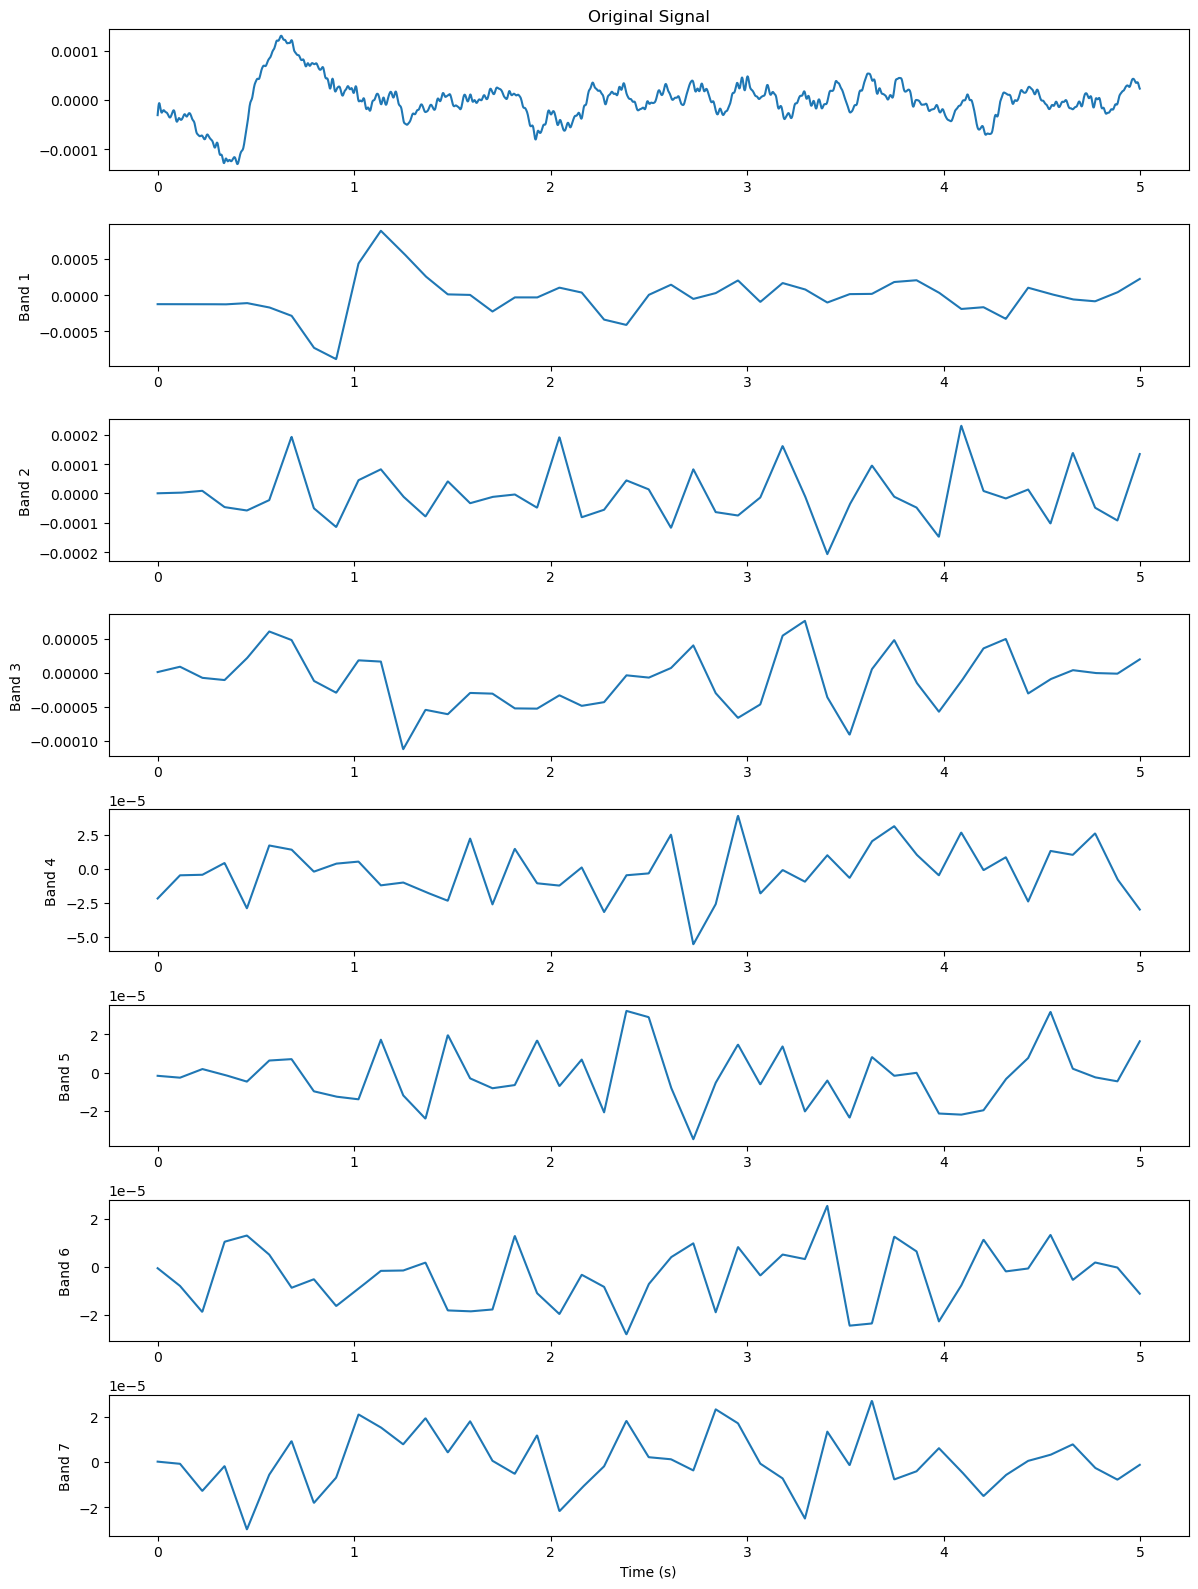

In [48]:
# Visualization: signal + TQWT subbands

# load one subject just for visualization
sub, filepath, label = manif[0]
raw = mne.io.read_raw_eeglab(filepath, preload=True, verbose='ERROR')

data = raw.get_data()
sig = data[0]  # first channel
sig = bandpass(sig)

segment = sig[:window_samples]

Q, R, J = estimate_tqwt_params(segment, fs_target)
bands = decompose_tqwt(segment, Q, R, J, fs_target)

def plot_decomposition(signal, subbands, fs=fs_target):
    t = np.arange(len(signal)) / fs
    n = len(subbands) + 1

    plt.figure(figsize=(12, 2*n))

    plt.subplot(n,1,1)
    plt.plot(t, signal)
    plt.title("Original Signal")

    for i, band in enumerate(subbands):
        plt.subplot(n,1,i+2)
        plt.plot(t, band)
        plt.ylabel(f"Band {i+1}")

    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

plot_decomposition(segment, bands)


In [49]:
# Cell 9: PyTorch Dataset
class EEGFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# standardize features (fit on all for now; better: fit on train in CV loop)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_scaled = sc.fit_transform(X)
np.save(save_dir/"scaler_mean.npy", sc.mean_)
np.save(save_dir/"scaler_scale.npy", sc.scale_)

dataset = EEGFeatureDataset(X_scaled, y)


In [50]:
# Cell 10: mixup augmentation
def mixup_data(x, y, alpha=0.4):
    '''Returns mixed inputs, pairs of targets, and lambda'''
    if alpha <= 0:
        return x, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)


In [51]:
# Cell 11: BiLSTM classifier
class BiLSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, n_layers=2, dropout=0.4):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        # treat features as a sequence by splitting into "timesteps"
        # choose a timestep length: we can partition features into channels*subbands steps
        # We'll set timesteps = n_channels_expected and features_per_step = input_dim / timesteps
        self.timesteps = n_channels_expected
        assert input_dim % self.timesteps == 0, "input_dim must be divisible by timesteps"
        self.feat_per_step = input_dim // self.timesteps
        self.lstm = nn.LSTM(self.feat_per_step, hidden_dim, num_layers=n_layers,
                            batch_first=True, bidirectional=True, dropout=dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim*2, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )
    def forward(self, x):
        # x: batch x input_dim
        b = x.size(0)
        x = x.view(b, self.timesteps, self.feat_per_step)  # batch x timesteps x feat_per_step
        out, _ = self.lstm(x)  # batch x timesteps x (2*hidden_dim)
        # use last timestep
        out = out[:, -1, :]
        out = self.fc(out).squeeze(1)
        return out  # logits


In [52]:
# Cell 12: training + 10-fold CV
from sklearn.utils.class_weight import compute_class_weight
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

INPUT_DIM = X_scaled.shape[1]
EPOCHS = 80
BATCH = 64
best_overall = {"auc":0.0, "model_path": None}

fold = 0
results = []

for train_idx, test_idx in skf.split(X_scaled, y):
    fold += 1
    print(f"\n===== Fold {fold} =====")
    X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # compute class weights for criterion
    cw = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    weight_tensor = torch.tensor([cw[0], cw[1]]).float().to(device)  # not directly used in BCEWithLogits
    # use pos_weight in BCEWithLogits for binary imbalance: pos_weight = weight of positive class
    # derive pos_weight = cw[1] / cw[0]
    pos_weight = torch.tensor([cw[1]/cw[0]]).float().to(device)

    train_ds = EEGFeatureDataset(X_train, y_train)
    test_ds = EEGFeatureDataset(X_test, y_test)
    train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True)
    test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False)

    model = BiLSTMClassifier(INPUT_DIM, hidden_dim=256, n_layers=2, dropout=0.4).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=5, factor=0.5)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)  # handles imbalance

    best_auc = 0.0
    best_model_path = save_dir / f"best_fold{fold}.pt"
    early_stop_count = 0

    for epoch in range(1, EPOCHS+1):
        model.train()
        epoch_loss = 0.0
        all_preds = []
        all_targets = []
        for xb, yb in train_loader:
            xb = xb.to(device).float()
            yb = yb.to(device).float()
            # mixup
            xb, ya, yb2, lam = mixup_data(xb, yb.long(), alpha=0.4)
            xb, ya, yb2 = xb.to(device).float(), ya.to(device).float(), yb2.to(device).float()
            optimizer.zero_grad()
            logits = model(xb)
            loss = mixup_criterion(criterion, logits, ya, yb2, lam)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()*xb.size(0)
            preds = torch.sigmoid(logits).detach().cpu().numpy()
            all_preds.extend(preds.tolist())
            all_targets.extend(ya.detach().cpu().numpy().tolist())
        epoch_loss /= len(train_loader.dataset)
        # eval
        model.eval()
        y_true = []
        y_score = []
        with torch.no_grad():
            for xb, yb in test_loader:
                xb = xb.to(device).float()
                logits = model(xb)
                probs = torch.sigmoid(logits).detach().cpu().numpy()
                y_score.extend(probs.tolist())
                y_true.extend(yb.numpy().tolist())
        # compute AUC
        try:
            auc = roc_auc_score(y_true, y_score)
        except:
            auc = 0.5
        print(f"Fold{fold} Epoch {epoch:02d} loss:{epoch_loss:.4f} val_auc:{auc:.4f}")
        scheduler.step(auc)

        # checkpoint
        if auc > best_auc:
            torch.save(model.state_dict(), best_model_path)
            best_auc = auc
            early_stop_count = 0
        else:
            early_stop_count += 1
        if early_stop_count >= 12:
            print("Early stopping.")
            break

    # load best model for fold and evaluate detailed metrics
    model.load_state_dict(torch.load(best_model_path))
    model.eval()
    y_true = []
    y_score = []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device).float()
            logits = model(xb)
            probs = torch.sigmoid(logits).detach().cpu().numpy()
            y_score.extend(probs.tolist())
            y_true.extend(yb.numpy().tolist())
    y_pred = [1 if p>=0.5 else 0 for p in y_score]
    auc = roc_auc_score(y_true, y_score)
    cm = confusion_matrix(y_true, y_pred)
    crep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    results.append({"fold":fold, "auc":auc, "cm":cm, "report":crep, "model_path":str(best_model_path)})
    print("Fold", fold, "AUC", auc, "CM\n", cm)
    # track best overall
    if auc > best_overall["auc"]:
        best_overall["auc"] = auc
        best_overall["model_path"] = str(best_model_path)

# save results summary
import pickle
with open(save_dir/"cv_results.pkl", "wb") as f:
    pickle.dump(results, f)
print("CV done. Best overall AUC:", best_overall["auc"], "model:", best_overall["model_path"])



===== Fold 1 =====
Fold1 Epoch 01 loss:0.5361 val_auc:0.8363
Fold1 Epoch 02 loss:0.4709 val_auc:0.8970
Fold1 Epoch 03 loss:0.4370 val_auc:0.9159
Fold1 Epoch 04 loss:0.4163 val_auc:0.9248
Fold1 Epoch 05 loss:0.3963 val_auc:0.9353
Fold1 Epoch 06 loss:0.3854 val_auc:0.9486
Fold1 Epoch 07 loss:0.3679 val_auc:0.9525
Fold1 Epoch 08 loss:0.3523 val_auc:0.9555
Fold1 Epoch 09 loss:0.3382 val_auc:0.9590
Fold1 Epoch 10 loss:0.3358 val_auc:0.9668
Fold1 Epoch 11 loss:0.3311 val_auc:0.9649
Fold1 Epoch 12 loss:0.3166 val_auc:0.9720
Fold1 Epoch 13 loss:0.3085 val_auc:0.9679
Fold1 Epoch 14 loss:0.3187 val_auc:0.9732
Fold1 Epoch 15 loss:0.3088 val_auc:0.9723
Fold1 Epoch 16 loss:0.2986 val_auc:0.9718
Fold1 Epoch 17 loss:0.3024 val_auc:0.9785
Fold1 Epoch 18 loss:0.2921 val_auc:0.9806
Fold1 Epoch 19 loss:0.2838 val_auc:0.9742
Fold1 Epoch 20 loss:0.2935 val_auc:0.9781
Fold1 Epoch 21 loss:0.2866 val_auc:0.9764
Fold1 Epoch 22 loss:0.2664 val_auc:0.9740
Fold1 Epoch 23 loss:0.2685 val_auc:0.9799
Fold1 Epoch 24

/tmp/ipykernel_7498/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold2 Epoch 01 loss:0.5375 val_auc:0.8388
Fold2 Epoch 02 loss:0.4829 val_auc:0.8896
Fold2 Epoch 03 loss:0.4431 val_auc:0.9131
Fold2 Epoch 04 loss:0.4351 val_auc:0.9247
Fold2 Epoch 05 loss:0.4112 val_auc:0.9360
Fold2 Epoch 06 loss:0.3948 val_auc:0.9531
Fold2 Epoch 07 loss:0.3788 val_auc:0.9521
Fold2 Epoch 08 loss:0.3620 val_auc:0.9592
Fold2 Epoch 09 loss:0.3535 val_auc:0.9648
Fold2 Epoch 10 loss:0.3501 val_auc:0.9661
Fold2 Epoch 11 loss:0.3429 val_auc:0.9666
Fold2 Epoch 12 loss:0.3260 val_auc:0.9722
Fold2 Epoch 13 loss:0.3302 val_auc:0.9734
Fold2 Epoch 14 loss:0.3289 val_auc:0.9717
Fold2 Epoch 15 loss:0.3154 val_auc:0.9754
Fold2 Epoch 16 loss:0.3114 val_auc:0.9740
Fold2 Epoch 17 loss:0.2999 val_auc:0.9736
Fold2 Epoch 18 loss:0.3087 val_auc:0.9786
Fold2 Epoch 19 loss:0.3101 val_auc:0.9770
Fold2 Epoch 20 loss:0.2946 val_auc:0.9778
Fold2 Epoch 21 loss:0.2913 val_auc:0.9750
Fold2 Epoch 22 loss:0.2889 val_auc:0.9794
Fold2 Epoch 23 loss:0.2789 val_auc:0.9798
Fold2 Epoch 24 loss:0.2617 val_auc

/tmp/ipykernel_7498/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold3 Epoch 01 loss:0.5402 val_auc:0.8449
Fold3 Epoch 02 loss:0.4730 val_auc:0.8929
Fold3 Epoch 03 loss:0.4430 val_auc:0.9141
Fold3 Epoch 04 loss:0.4228 val_auc:0.9251
Fold3 Epoch 05 loss:0.4076 val_auc:0.9340
Fold3 Epoch 06 loss:0.3923 val_auc:0.9449
Fold3 Epoch 07 loss:0.3737 val_auc:0.9542
Fold3 Epoch 08 loss:0.3705 val_auc:0.9508
Fold3 Epoch 09 loss:0.3695 val_auc:0.9578
Fold3 Epoch 10 loss:0.3474 val_auc:0.9682
Fold3 Epoch 11 loss:0.3479 val_auc:0.9627
Fold3 Epoch 12 loss:0.3396 val_auc:0.9690
Fold3 Epoch 13 loss:0.3292 val_auc:0.9672
Fold3 Epoch 14 loss:0.3169 val_auc:0.9716
Fold3 Epoch 15 loss:0.3111 val_auc:0.9727
Fold3 Epoch 16 loss:0.3092 val_auc:0.9743
Fold3 Epoch 17 loss:0.3029 val_auc:0.9681
Fold3 Epoch 18 loss:0.3082 val_auc:0.9726
Fold3 Epoch 19 loss:0.3064 val_auc:0.9739
Fold3 Epoch 20 loss:0.2969 val_auc:0.9723
Fold3 Epoch 21 loss:0.2893 val_auc:0.9761
Fold3 Epoch 22 loss:0.2943 val_auc:0.9778
Fold3 Epoch 23 loss:0.2901 val_auc:0.9757
Fold3 Epoch 24 loss:0.2818 val_auc

...

/tmp/ipykernel_7498/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold9 Epoch 01 loss:0.5382 val_auc:0.8630
Fold9 Epoch 02 loss:0.4676 val_auc:0.9028
Fold9 Epoch 03 loss:0.4396 val_auc:0.9173
Fold9 Epoch 04 loss:0.4217 val_auc:0.9170
Fold9 Epoch 05 loss:0.4118 val_auc:0.9392
Fold9 Epoch 06 loss:0.3909 val_auc:0.9525
Fold9 Epoch 07 loss:0.3882 val_auc:0.9568
Fold9 Epoch 08 loss:0.3569 val_auc:0.9603
Fold9 Epoch 09 loss:0.3559 val_auc:0.9659
Fold9 Epoch 10 loss:0.3392 val_auc:0.9660
Fold9 Epoch 11 loss:0.3365 val_auc:0.9685
Fold9 Epoch 12 loss:0.3219 val_auc:0.9732
Fold9 Epoch 13 loss:0.3311 val_auc:0.9764
Fold9 Epoch 14 loss:0.3158 val_auc:0.9765
Fold9 Epoch 15 loss:0.2939 val_auc:0.9748
Fold9 Epoch 16 loss:0.2897 val_auc:0.9773
Fold9 Epoch 17 loss:0.3023 val_auc:0.9754
Fold9 Epoch 18 loss:0.3039 val_auc:0.9779
Fold9 Epoch 19 loss:0.2883 val_auc:0.9769
Fold9 Epoch 20 loss:0.2989 val_auc:0.9775
Fold9 Epoch 21 loss:0.2814 val_auc:0.9765
Fold9 Epoch 22 loss:0.2774 val_auc:0.9737
Fold9 Epoch 23 loss:0.2816 val_auc:0.9754
Fold9 Epoch 24 loss:0.2786 val_auc

/tmp/ipykernel_7498/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold10 Epoch 01 loss:0.5337 val_auc:0.8484
Fold10 Epoch 02 loss:0.4728 val_auc:0.9004
Fold10 Epoch 03 loss:0.4428 val_auc:0.9179
Fold10 Epoch 04 loss:0.4275 val_auc:0.9325
Fold10 Epoch 05 loss:0.4105 val_auc:0.9387
Fold10 Epoch 06 loss:0.3935 val_auc:0.9487
Fold10 Epoch 07 loss:0.3818 val_auc:0.9515
Fold10 Epoch 08 loss:0.3634 val_auc:0.9566
Fold10 Epoch 09 loss:0.3457 val_auc:0.9632
Fold10 Epoch 10 loss:0.3595 val_auc:0.9633
Fold10 Epoch 11 loss:0.3477 val_auc:0.9698
Fold10 Epoch 12 loss:0.3241 val_auc:0.9670
Fold10 Epoch 13 loss:0.3292 val_auc:0.9741
Fold10 Epoch 14 loss:0.3056 val_auc:0.9715
Fold10 Epoch 15 loss:0.3147 val_auc:0.9766
Fold10 Epoch 16 loss:0.3076 val_auc:0.9760
Fold10 Epoch 17 loss:0.3060 val_auc:0.9781
Fold10 Epoch 18 loss:0.3054 val_auc:0.9810
Fold10 Epoch 19 loss:0.2866 val_auc:0.9785
Fold10 Epoch 20 loss:0.2887 val_auc:0.9806
Fold10 Epoch 21 loss:0.2928 val_auc:0.9800
Fold10 Epoch 22 loss:0.2959 val_auc:0.9779
Fold10 Epoch 23 loss:0.2770 val_auc:0.9767
Fold10 Epoc

/tmp/ipykernel_7498/1701392612.py:92: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


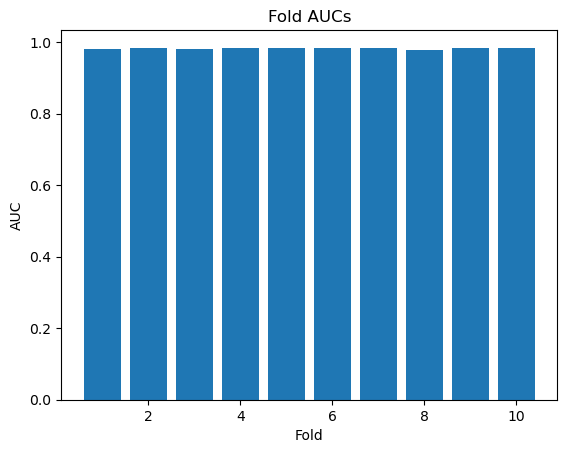

Best fold: 6 AUC: 0.9844976155584373
Classification report (best fold):
              precision    recall  f1-score      support
0              0.931677  0.925926  0.928793   972.000000
1              0.938828  0.943638  0.941227  1171.000000
accuracy       0.935604  0.935604  0.935604     0.935604
macro avg      0.935252  0.934782  0.935010  2143.000000
weighted avg   0.935584  0.935604  0.935587  2143.000000


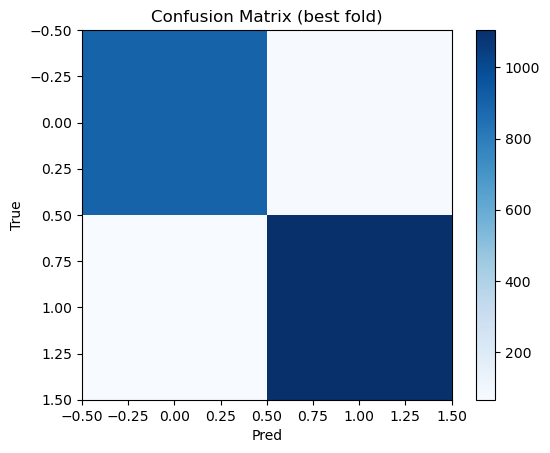

In [53]:
# Cell 13: simple plotting of fold metrics
import matplotlib.pyplot as plt
with open(save_dir/"cv_results.pkl","rb") as f:
    res = pickle.load(f)

# aggregate AUCs
aucs = [r['auc'] for r in res]
plt.figure()
plt.bar(range(1,len(aucs)+1), aucs)
plt.xlabel("Fold"); plt.ylabel("AUC"); plt.title("Fold AUCs")
plt.savefig(save_dir/"fold_aucs.png", dpi=150)
plt.show()

# show confusion matrix of best fold
best = max(res, key=lambda x: x['auc'])
print("Best fold:", best['fold'], "AUC:", best['auc'])
print("Classification report (best fold):")
print(pd.DataFrame(best['report']).T)
cm = best['cm']
plt.figure()
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar()
plt.xlabel("Pred"); plt.ylabel("True"); plt.title("Confusion Matrix (best fold)")
plt.savefig(save_dir/"best_confusion.png", dpi=150)
plt.show()


In [54]:
# Cell 14: final save and example report
print("Best model saved at:", best_overall["model_path"])
# load and show sample predictions with that model (if desired)
final_model = BiLSTMClassifier(INPUT_DIM).to(device)
final_model.load_state_dict(torch.load(best_overall["model_path"]))
final_model.eval()
# Optionally export to ONNX if requested (skipped per choice)


Best model saved at: results_bilstm/best_fold6.pt


/tmp/ipykernel_7498/2083957647.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  final_model.load_state_dict(torch.load(best_overall["model_path"]))


BiLSTMClassifier(
  (lstm): LSTM(28, 256, num_layers=2, batch_first=True, dropout=0.4, bidirectional=True)
  (fc): Sequential(
    (0): Linear(in_features=512, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)

Best fold: 6 | AUC: 0.984


/tmp/ipykernel_7498/3696722634.py:33: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


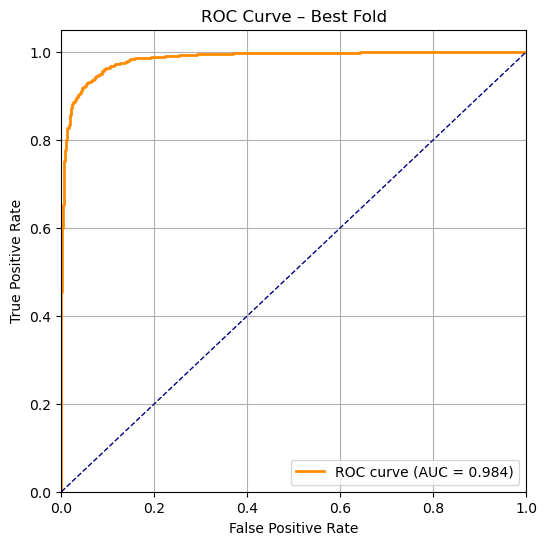

In [55]:
# Cell A: Plot ROC curve for best fold
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Load results
with open(save_dir / "cv_results.pkl", "rb") as f:
    res = pickle.load(f)

best = max(res, key=lambda x: x['auc'])
y_true = []
y_score = []

# Reload test predictions for best fold
best_fold = best['fold']
print(f"Best fold: {best_fold} | AUC: {best['auc']:.3f}")

# Extract test data from saved fold (re-run same split for ROC)
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
fold = 0
for train_idx, test_idx in skf.split(X_scaled, y):
    fold += 1
    if fold == best_fold:
        X_test = X_scaled[test_idx]
        y_test = y[test_idx]
        break

# Reload best model
best_model_path = best['model_path']
model = BiLSTMClassifier(X_scaled.shape[1]).to(device)
model.load_state_dict(torch.load(best_model_path))
model.eval()

with torch.no_grad():
    xb = torch.from_numpy(X_test).to(device).float()
    preds = torch.sigmoid(model(xb)).cpu().numpy().flatten()

fpr, tpr, thresholds = roc_curve(y_test, preds)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0,1], [0,1], color='navy', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Best Fold')
plt.legend(loc="lower right")
plt.grid(True)
plt.savefig(save_dir / "roc_curve_best_fold.png", dpi=150)
plt.show()
